In [2]:
import numpy as np
import pandas as pd
from  pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns   
from scipy.stats import chi2_contingency
from scipy .stats import f_oneway
import sys

sys.path.append(str(Path.cwd().parent))
from helpers import chi2_test, anova_test, are_there_outliers

dataDirectoty = Path.cwd().parents[1] / 'data'

trainData = pd.read_csv(dataDirectoty / 'train.csv').copy()

In [3]:
print(trainData.duplicated().sum())

0


In [4]:
print(trainData.head(10))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

In [5]:
print(trainData.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None


In [6]:
print(trainData.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [7]:
print(trainData.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


## Feature analysis

### Categorical features

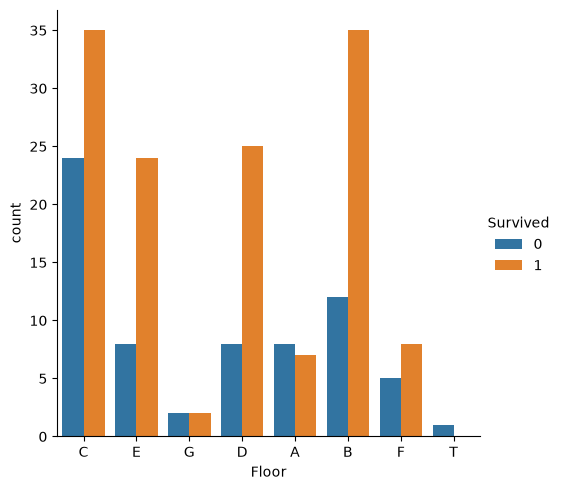

In [8]:
trainDataWithFloorColumn = trainData
trainDataWithFloorColumn['Floor'] = trainData['Cabin'].str[0]
sns.catplot(data=trainDataWithFloorColumn, kind='count', x='Floor', hue='Survived')
plt.show()

--------------------
Name: Sex
Type: Categorical
% of missing values: 0.0%
Cardinality and frequency: Sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64
Chi² test:
	H0: Survived and Sex are independent
	H1: Survived and Sex are dependent
	We reject H0
	P value: 1.1973570627755645e-58


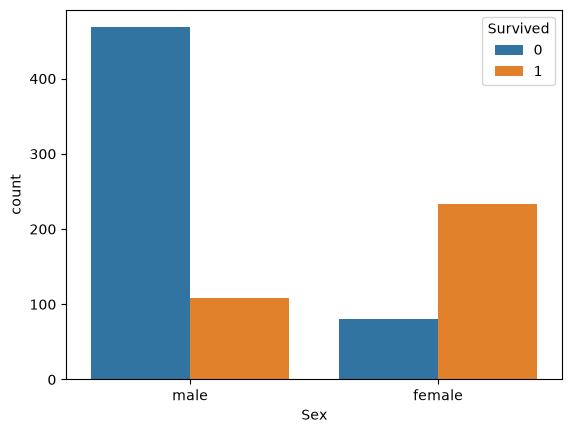

--------------------
Name: Survived
Type: Categorical
% of missing values: 0.0%
Cardinality and frequency: Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


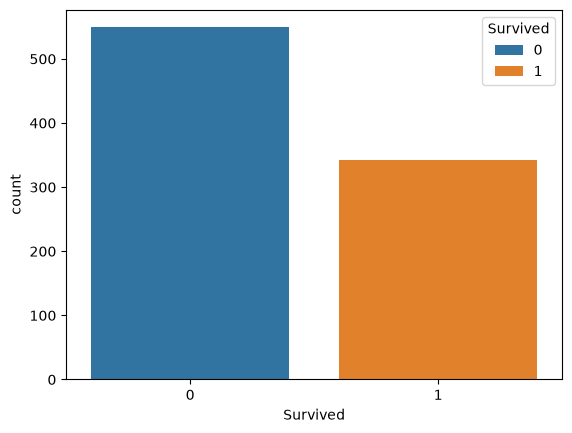

--------------------
Name: Embarked
Type: Categorical
% of missing values: 0.22446689113355783%
Cardinality and frequency: Embarked
S    0.724409
C    0.188976
Q    0.086614
Name: proportion, dtype: float64
Chi² test:
	H0: Survived and Embarked are independent
	H1: Survived and Embarked are dependent
	We reject H0
	P value: 1.769922284120912e-06


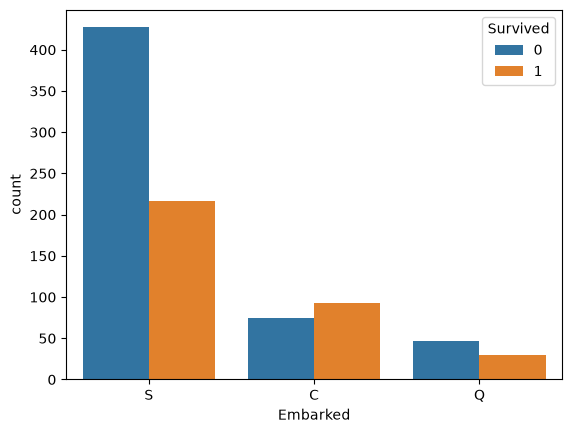

--------------------
Name: Pclass
Type: Categorical
% of missing values: 0.0%
Cardinality and frequency: Pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64
Chi² test:
	H0: Survived and Pclass are independent
	H1: Survived and Pclass are dependent
	We reject H0
	P value: 4.549251711298793e-23


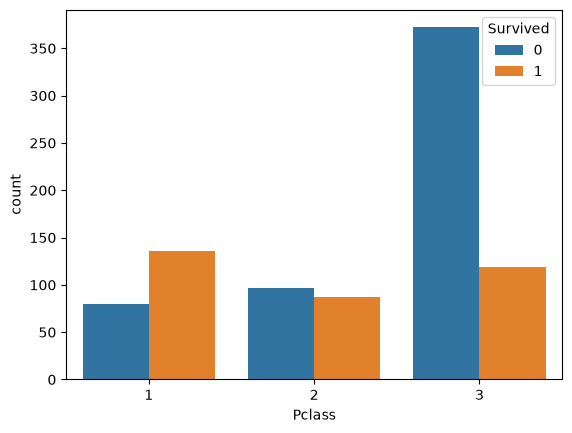

--------------------
Name: SibSp
Type: Categorical
% of missing values: 0.0%
Cardinality and frequency: SibSp
0    0.682379
1    0.234568
2    0.031425
4    0.020202
3    0.017957
8    0.007856
5    0.005612
Name: proportion, dtype: float64
Chi² test:
	H0: Survived and SibSp are independent
	H1: Survived and SibSp are dependent
	We reject H0
	P value: 1.5585810465902116e-06


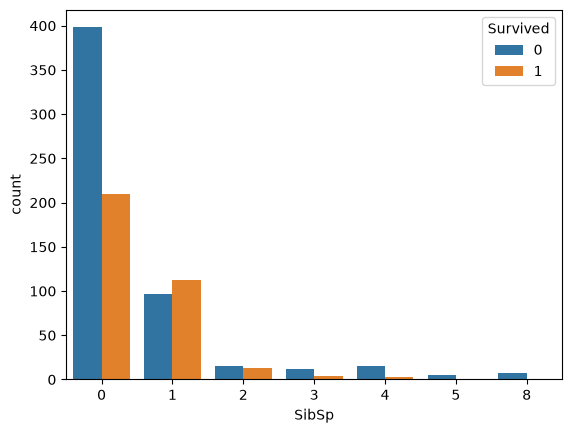

--------------------
Name: Parch
Type: Categorical
% of missing values: 0.0%
Cardinality and frequency: Parch
0    0.760943
1    0.132435
2    0.089787
5    0.005612
3    0.005612
4    0.004489
6    0.001122
Name: proportion, dtype: float64
Chi² test:
	H0: Survived and Parch are independent
	H1: Survived and Parch are dependent
	We reject H0
	P value: 9.703526421039997e-05


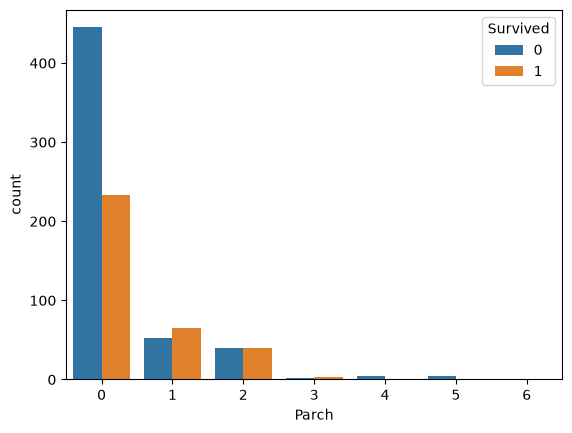

--------------------


In [9]:
categorical_cols = ['Sex', 'Survived', 'Embarked', 'Pclass', 'SibSp', 'Parch']
print("--------------------")
for col in categorical_cols:
    print(f"Name: {col}")
    print("Type: Categorical")
    print(f"% of missing values: {trainData[col].isna().mean()*100}%")
    print(f"Cardinality and frequency: {trainData[col].value_counts(normalize=True,)}")
    
    if(col!='Survived'):
        chi2_test(trainData, 'Survived', col, 0.05)

    sns.countplot(data=trainData, x=col, hue="Survived")
    plt.show()
    print("--------------------")

### Numerical features

--------------------
Name: Age
Type: numerical
Are there outliers?: 0      True
1      True
2      True
3      True
4      True
       ... 
886    True
887    True
888    True
889    True
890    True
Name: Age, Length: 891, dtype: bool
ANOVA test:
	H0: Survived and Age are independent
	H1: Survived and Age are dependent
	We reject H0
	F: 4.271194933815904, p value: 0.039124654013482356


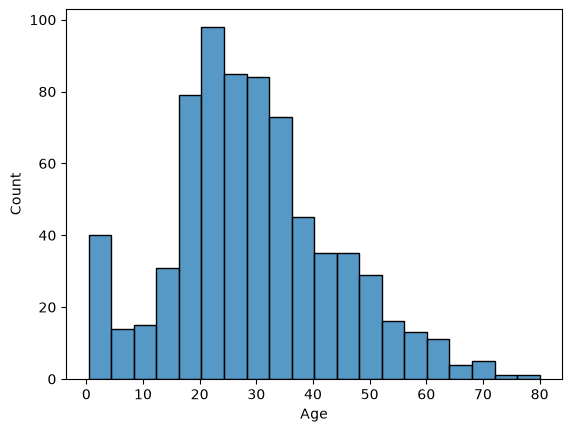

--------------------
Name: Fare
Type: numerical
Are there outliers?: 0      True
1      True
2      True
3      True
4      True
       ... 
886    True
887    True
888    True
889    True
890    True
Name: Fare, Length: 891, dtype: bool
ANOVA test:
	H0: Survived and Fare are independent
	H1: Survived and Fare are dependent
	We reject H0
	F: 63.03076422804447, p value: 6.120189341924331e-15


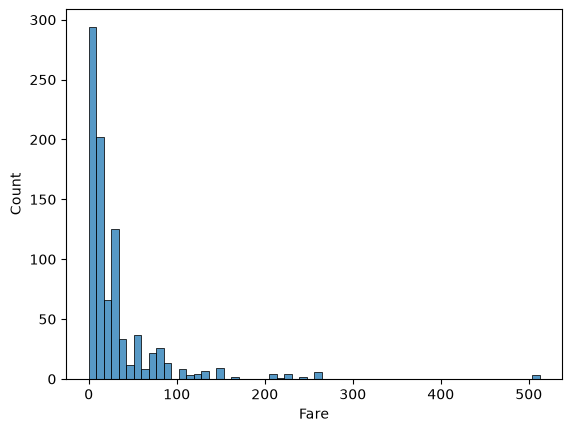

--------------------


In [10]:


numerical_cols = ['Age', 'Fare']
print("--------------------")
for col in numerical_cols:
    print(f"Name: {col}")
    print("Type: numerical")
    print(f"Are there outliers?: {are_there_outliers(trainData, col)}")
    anova_test(trainData, 'Survived', col, 0.05)
    sns.histplot(data=trainData, x=col)
    plt.show()
    print("--------------------")

<Axes: xlabel='Age', ylabel='Fare'>

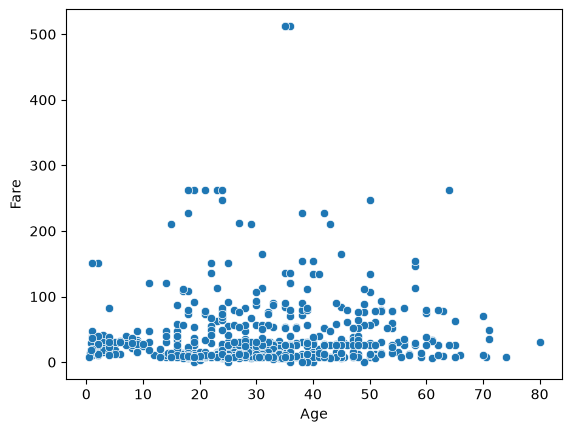

In [12]:
sns.scatterplot(data=trainData, x='Age', y='Fare')